# Chatbot Edukasi Sistem Informasi — Fine-tuning Qwen2.5 dengan LoRA

**Mata Kuliah: Sistem Informasi Berbasis Kecerdasan Buatan**

**Kelompok:**
1. Muhammad Ushaim Mukmin Kasim | NIM: 255150407111097
2. Abner Benedict Javier Siahaan  | NIM: 255150407111105

**Alur aplikasi (Pilihan 1 — Text AI):** `Teks (pertanyaan) → Qwen2.5 + LoRA → Teks (jawaban)`

**Cara pakai di Google Colab:**
1. Menu *Runtime → Change runtime type → T4 GPU*.
2. Jalankan semua sel dari atas ke bawah (*Runtime → Run all*).
3. Sel terakhir menjalankan antarmuka Gradio (akan muncul link publik).

**Tahapan:** (1) Masalah & domain → (2) Input/Output → (3) Dataset → (4) Preprocessing → (5) Model → (6) Baseline → (7) Fine-tuning LoRA → (8) Inference → (9) Evaluasi → (10) Gradio.

## 1–3. Permasalahan, Input/Output, dan Dataset

- **Permasalahan:** Mahasiswa pemula Sistem Informasi sering membutuhkan penjelasan singkat dan konsisten tentang konsep dasar (basis data, SDLC, UML, ERP, keamanan informasi, dsb.).
- **Domain:** Edukasi Sistem Informasi.
- **Input:** teks pertanyaan dalam Bahasa Indonesia. **Output:** teks jawaban singkat, jelas, dan terstruktur.
- **Dataset:** dibuat sendiri (pasangan *pertanyaan–jawaban*), lalu dibagi menjadi data latih dan data uji.

In [ ]:
!pip -q install -U transformers peft accelerate datasets gradio torchao

In [ ]:
import json, random, re, torch
from collections import Counter

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
print("CUDA tersedia:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-")

In [ ]:
# ===== DATASET BUATAN SENDIRI =====
DATA = [
("Apa itu sistem informasi?", "Sistem informasi adalah kombinasi dari manusia, perangkat keras, perangkat lunak, data, dan prosedur yang bekerja bersama untuk mengumpulkan, mengolah, menyimpan, dan menyebarkan informasi guna mendukung operasional dan pengambilan keputusan organisasi."),
("Apa saja komponen sistem informasi?", "Komponen sistem informasi meliputi: 1) perangkat keras, 2) perangkat lunak, 3) data, 4) prosedur, dan 5) manusia (pengguna dan pengelola sistem)."),
("Apa perbedaan data dan informasi?", "Data adalah fakta mentah yang belum diolah, sedangkan informasi adalah data yang sudah diolah sehingga bermakna dan berguna untuk pengambilan keputusan."),
("Apa itu SDLC?", "SDLC (System Development Life Cycle) adalah siklus pengembangan sistem yang terdiri dari tahap perencanaan, analisis, perancangan, implementasi, pengujian, dan pemeliharaan sistem."),
("Apa itu metode waterfall?", "Waterfall adalah model SDLC yang tahapannya berjalan berurutan dari atas ke bawah, yaitu analisis kebutuhan, desain, implementasi, pengujian, dan pemeliharaan. Tahap berikutnya baru dimulai setelah tahap sebelumnya selesai."),
("Apa itu metode agile?", "Agile adalah pendekatan pengembangan perangkat lunak yang iteratif dan inkremental, dengan siklus pendek, kolaborasi erat dengan pengguna, dan kemampuan beradaptasi terhadap perubahan kebutuhan."),
("Apa itu Scrum?", "Scrum adalah kerangka kerja agile yang membagi pekerjaan ke dalam sprint berdurasi singkat, dengan peran Product Owner, Scrum Master, dan Development Team, serta kegiatan seperti sprint planning, daily scrum, sprint review, dan retrospective."),
("Apa itu ERD?", "ERD (Entity Relationship Diagram) adalah diagram yang menggambarkan struktur basis data melalui entitas, atribut, dan relasi antar entitas."),
("Apa itu primary key?", "Primary key adalah atribut atau kombinasi atribut yang nilainya unik dan tidak boleh kosong, sehingga dapat mengidentifikasi setiap baris dalam sebuah tabel."),
("Apa itu foreign key?", "Foreign key adalah atribut dalam suatu tabel yang merujuk ke primary key tabel lain, sehingga menghubungkan kedua tabel dan menjaga integritas referensial."),
("Apa itu normalisasi basis data?", "Normalisasi adalah proses menyusun tabel basis data untuk mengurangi redundansi dan anomali data, melalui tahapan bentuk normal seperti 1NF, 2NF, dan 3NF."),
("Apa itu DBMS?", "DBMS (Database Management System) adalah perangkat lunak untuk membuat, mengelola, dan mengakses basis data, contohnya MySQL, PostgreSQL, dan Oracle."),
("Apa itu SQL?", "SQL (Structured Query Language) adalah bahasa standar untuk mengelola basis data relasional, misalnya untuk menambah, membaca, mengubah, dan menghapus data dengan perintah INSERT, SELECT, UPDATE, dan DELETE."),
("Apa fungsi perintah JOIN pada SQL?", "JOIN digunakan untuk menggabungkan baris dari dua tabel atau lebih berdasarkan kolom yang berhubungan, misalnya INNER JOIN, LEFT JOIN, dan RIGHT JOIN."),
("Apa itu ERP?", "ERP (Enterprise Resource Planning) adalah sistem terintegrasi yang mengelola proses bisnis inti seperti keuangan, produksi, persediaan, SDM, dan penjualan dalam satu basis data terpusat."),
("Apa itu CRM?", "CRM (Customer Relationship Management) adalah sistem dan strategi untuk mengelola interaksi dengan pelanggan guna meningkatkan kepuasan, loyalitas, dan penjualan."),
("Apa itu SCM?", "SCM (Supply Chain Management) adalah pengelolaan aliran barang, informasi, dan keuangan dari pemasok hingga ke pelanggan agar rantai pasok berjalan efisien."),
("Apa itu sistem pendukung keputusan?", "Sistem pendukung keputusan (DSS) adalah sistem informasi interaktif yang membantu manajer mengambil keputusan semi-terstruktur dengan memanfaatkan data, model analisis, dan antarmuka yang mudah digunakan."),
("Apa itu sistem informasi manajemen?", "Sistem informasi manajemen (SIM) adalah sistem yang menyediakan laporan rutin dan ringkasan data operasional untuk membantu manajer memantau dan mengendalikan kegiatan organisasi."),
("Apa itu transaction processing system?", "Transaction processing system (TPS) adalah sistem yang mencatat dan memproses transaksi harian organisasi, seperti penjualan, pembayaran, dan pemesanan, secara akurat dan cepat."),
("Apa itu UML?", "UML (Unified Modeling Language) adalah bahasa pemodelan visual standar untuk merancang dan mendokumentasikan sistem, misalnya use case diagram, class diagram, activity diagram, dan sequence diagram."),
("Apa itu use case diagram?", "Use case diagram menggambarkan interaksi antara aktor (pengguna atau sistem lain) dengan fungsi-fungsi yang disediakan sistem, sehingga menunjukkan kebutuhan fungsional secara garis besar."),
("Apa itu class diagram?", "Class diagram menggambarkan struktur sistem berorientasi objek melalui kelas, atribut, metode, serta hubungan antar kelas seperti asosiasi, agregasi, dan pewarisan."),
("Apa itu sequence diagram?", "Sequence diagram menggambarkan urutan pesan atau interaksi antar objek dalam satu skenario tertentu berdasarkan waktu."),
("Apa itu DFD?", "DFD (Data Flow Diagram) adalah diagram yang menggambarkan aliran data dalam sistem melalui proses, penyimpanan data, entitas eksternal, dan arus data."),
("Apa itu flowchart?", "Flowchart adalah diagram yang menggambarkan alur langkah-langkah proses atau algoritma menggunakan simbol-simbol standar yang dihubungkan dengan panah."),
("Apa itu UI dan UX?", "UI (User Interface) adalah tampilan visual yang berinteraksi dengan pengguna, sedangkan UX (User Experience) adalah keseluruhan pengalaman pengguna saat memakai produk, termasuk kemudahan dan kepuasan."),
("Apa itu MVC?", "MVC (Model-View-Controller) adalah pola arsitektur yang memisahkan aplikasi menjadi Model (data dan logika bisnis), View (tampilan), dan Controller (penghubung yang mengatur alur permintaan)."),
("Apa itu PHP?", "PHP adalah bahasa pemrograman sisi server yang banyak digunakan untuk membangun aplikasi web dinamis dan terhubung dengan basis data seperti MySQL."),
("Apa itu API?", "API (Application Programming Interface) adalah antarmuka yang memungkinkan dua aplikasi saling berkomunikasi dan bertukar data dengan aturan yang telah ditentukan."),
("Apa itu framework?", "Framework adalah kerangka kerja berisi kumpulan kode, struktur, dan aturan siap pakai yang mempercepat pengembangan aplikasi, contohnya Laravel untuk PHP."),
("Apa itu CIA triad dalam keamanan informasi?", "CIA triad terdiri dari Confidentiality (kerahasiaan), Integrity (keutuhan), dan Availability (ketersediaan), yang menjadi tiga prinsip dasar keamanan informasi."),
("Apa itu enkripsi?", "Enkripsi adalah proses mengubah data asli (plaintext) menjadi bentuk yang tidak dapat dibaca (ciphertext) menggunakan algoritma dan kunci, sehingga hanya pihak berwenang yang dapat membacanya."),
("Apa itu phishing?", "Phishing adalah serangan siber yang menipu korban, biasanya lewat email atau pesan palsu, agar memberikan data sensitif seperti kata sandi atau nomor kartu."),
("Mengapa backup data penting?", "Backup penting agar data dapat dipulihkan ketika terjadi kerusakan, kehilangan, serangan siber, atau kesalahan manusia, sehingga operasional organisasi tetap berjalan."),
("Apa itu cloud computing?", "Cloud computing adalah penyediaan layanan komputasi seperti server, penyimpanan, dan aplikasi melalui internet secara on-demand, dengan model layanan IaaS, PaaS, dan SaaS."),
("Apa itu e-commerce?", "E-commerce adalah kegiatan jual beli barang atau jasa melalui jaringan elektronik seperti internet, misalnya marketplace dan toko online."),
("Apa itu big data?", "Big data adalah kumpulan data berukuran sangat besar, beragam, dan cepat bertambah, yang dicirikan oleh volume, velocity, dan variety, sehingga memerlukan teknologi khusus untuk mengolahnya."),
("Apa itu data warehouse?", "Data warehouse adalah penyimpanan data terpusat yang mengintegrasikan data dari berbagai sumber dan disusun untuk keperluan analisis serta pelaporan."),
("Apa itu business intelligence?", "Business intelligence adalah proses dan teknologi untuk mengolah data bisnis menjadi wawasan melalui dashboard, laporan, dan analisis guna mendukung keputusan."),
("Apa itu startup?", "Startup adalah perusahaan rintisan yang baru berdiri dan berfokus mengembangkan produk atau layanan inovatif dengan model bisnis yang dapat tumbuh pesat."),
("Apa itu MVP pada startup?", "MVP (Minimum Viable Product) adalah versi produk paling sederhana yang memiliki fitur inti untuk diuji ke pengguna awal, sehingga startup dapat belajar dari umpan balik dengan biaya dan waktu minimal."),
("Apa itu tata kelola teknologi informasi?", "Tata kelola TI adalah kerangka kebijakan, struktur, dan proses yang memastikan investasi dan penggunaan TI selaras dengan tujuan organisasi, risikonya terkendali, dan manfaatnya optimal."),
("Apa itu COBIT?", "COBIT adalah kerangka kerja tata kelola dan manajemen TI yang membantu organisasi menyelaraskan TI dengan tujuan bisnis, mengelola risiko, dan mengukur kinerja."),
("Apa itu black box testing?", "Black box testing adalah pengujian perangkat lunak yang berfokus pada input dan output sistem berdasarkan spesifikasi, tanpa melihat struktur kode di dalamnya."),
("Apa itu requirement dalam pengembangan sistem?", "Requirement adalah kebutuhan yang harus dipenuhi sistem, terdiri dari kebutuhan fungsional (fitur yang harus ada) dan kebutuhan non-fungsional (kinerja, keamanan, kemudahan penggunaan)."),
("Apa itu stakeholder?", "Stakeholder adalah pihak yang berkepentingan atau terdampak oleh sebuah sistem atau proyek, seperti pengguna, manajemen, pengembang, dan pelanggan."),
("Apa itu artificial intelligence?", "Artificial intelligence (AI) adalah cabang ilmu komputer yang membuat sistem mampu melakukan tugas yang biasanya membutuhkan kecerdasan manusia, seperti memahami bahasa, mengenali pola, dan mengambil keputusan."),
("Apa itu machine learning?", "Machine learning adalah bagian dari AI yang memungkinkan komputer belajar pola dari data untuk membuat prediksi atau keputusan tanpa diprogram secara eksplisit untuk setiap aturan."),
("Apa itu large language model?", "Large language model (LLM) adalah model AI berbasis jaringan saraf berukuran besar yang dilatih pada data teks dalam jumlah besar untuk memahami dan menghasilkan bahasa alami."),
("Apa itu fine-tuning?", "Fine-tuning adalah proses melanjutkan pelatihan model pretrained dengan dataset khusus agar model menyesuaikan diri dengan tugas atau domain tertentu."),
("Apa itu LoRA?", "LoRA (Low-Rank Adaptation) adalah teknik fine-tuning efisien yang membekukan bobot model asli dan hanya melatih matriks berperingkat rendah tambahan, sehingga kebutuhan memori dan waktu pelatihan jauh lebih kecil."),
]
print("Total data:", len(DATA))

## 4. Preprocessing Dataset
Data dibersihkan, diacak, dibagi (±85% latih / 15% uji), disimpan sebagai JSONL, lalu diubah ke format *chat template* Qwen. Pada label, bagian *prompt* di-mask (`-100`) sehingga model hanya belajar menghasilkan **jawaban**.

In [ ]:
def clean(t): return re.sub(r"\s+", " ", t).strip()

data = [{"instruction": clean(q), "output": clean(a)} for q, a in DATA]
data = list({d["instruction"]: d for d in data}.values())
random.shuffle(data)

n_test = max(6, int(0.15 * len(data)))
test_data, train_data = data[:n_test], data[n_test:]
print(f"Latih: {len(train_data)} | Uji: {len(test_data)}")

for name, d in [("train", train_data), ("test", test_data)]:
    with open(f"{name}.jsonl", "w", encoding="utf-8") as f:
        for r in d: f.write(json.dumps(r, ensure_ascii=False) + "\n")

## 5–6. Memilih & Memuat Model Pretrained (Qwen2.5-Instruct)
Model dasar: **Qwen/Qwen2.5-1.5B-Instruct** (cukup ringan untuk GPU T4 gratis). Jika memori habis, ganti ke `Qwen/Qwen2.5-0.5B-Instruct`.

In [ ]:
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Bersihkan sisa-sisa model lama dari memori GPU (VRAM)
try:
    del model
except NameError:
    pass
try:
    del trainer
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
SYSTEM_PROMPT = ("Kamu adalah asisten edukasi Sistem Informasi untuk mahasiswa. "
                 "Jawablah dalam Bahasa Indonesia dengan singkat, jelas, dan akurat.")

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16).to("cuda")
model.config.use_cache = False
print("Parameter model:", round(sum(p.numel() for p in model.parameters())/1e6), "juta")

In [ ]:
@torch.no_grad()
def ask(question, max_new_tokens=200):
    model.eval()
    model.config.use_cache = True
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(model.device)
    with torch.autocast("cuda", dtype=torch.float16):
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             repetition_penalty=1.05, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

# Baseline: model pretrained SEBELUM fine-tuning, pada data uji
base_answers = {d["instruction"]: ask(d["instruction"]) for d in test_data}
for q, a in list(base_answers.items())[:3]:
    print("Q:", q, "\nBASE:", a, "\n" + "-"*60)

Q: Apa itu foreign key? 
BASE: Foreign key adalah sebuah kolom dalam tabel database yang menghubungkan antara dua tabel. Ini digunakan untuk menghubungkan data dari satu tabel ke tabel lainnya dalam basis data. Misalnya, jika tabel A memiliki kolom "customer_id" dan tabel B memiliki kolom "customer_id", maka "customer_id" di tabel A dapat menjadi foreign key yang menghubungkan kedua tabel tersebut. 
------------------------------------------------------------
Q: Apa itu sequence diagram? 
BASE: Sequence diagram adalah diagram yang digunakan dalam pengembangan sumber daya komputer untuk menunjukkan bagaimana objek-objek berinteraksi satu sama lain dalam suatu sistem. Ini membantu dalam memahami cara kerja dari sistem atau aplikasi, termasuk bagaimana data diterima, diproses, dan dikirimkan antara objek-objek. 
------------------------------------------------------------
Q: Apa itu flowchart? 
BASE: Flowchart adalah gambar atau diagram yang digunakan untuk menggambarkan proses atau alur 

## 7. Fine-tuning dengan LoRA (Parameter-Efficient Fine-Tuning)

In [ ]:
from peft import LoraConfig, get_peft_model
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq
from datasets import Dataset

MAX_LEN = 512

def build_example(r):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": r["instruction"]}]
    prompt = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full = prompt + r["output"] + "<|im_end|>"
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tok(full, add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = ([-100] * len(p_ids) + f_ids[len(p_ids):])[:len(f_ids)]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels}

train_ds = Dataset.from_list(train_data).map(build_example, remove_columns=["instruction", "output"])

lora_cfg = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()

Map:   0%|          | 0/45 [00:00<?, ? examples/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


In [ ]:
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

args = TrainingArguments(
    output_dir="qwen-si-lora",
    num_train_epochs=6,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=2,
    logging_steps=2,
    save_strategy="no",
    fp16=True,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100)
)

trainer.train()

model.save_pretrained("qwen-si-lora-adapter")
tok.save_pretrained("qwen-si-lora-adapter")
print("Adapter LoRA tersimpan di folder: qwen-si-lora-adapter")

Step,Training Loss
2,1.265447
4,1.512064
6,1.227115
8,0.905495
10,0.976633
12,0.944250
14,0.649580
16,0.591761
18,0.604581
20,0.421500


Adapter LoRA tersimpan di folder: qwen-si-lora-adapter


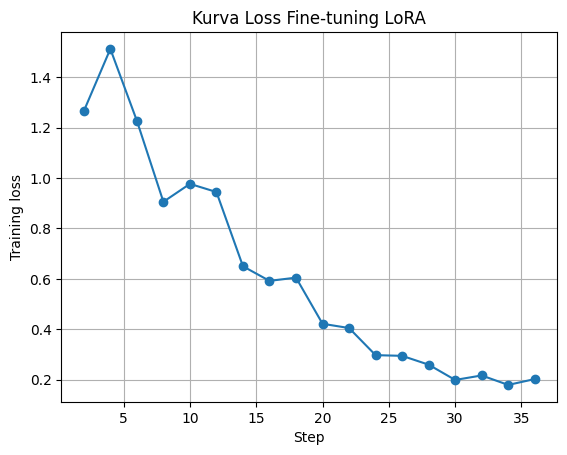

In [ ]:
import matplotlib.pyplot as plt
logs = [l for l in trainer.state.log_history if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.xlabel("Step"); plt.ylabel("Training loss"); plt.title("Kurva Loss Fine-tuning LoRA"); plt.grid(True)
plt.savefig("loss_curve.png", dpi=150); plt.show()

## 8. Inference pada Data Baru
Pertanyaan di bawah ini **tidak ada** di dataset latih.

In [ ]:
new_questions = [
    "Jelaskan apa itu sistem informasi akuntansi.",
    "Apa perbedaan primary key dan foreign key?",
    "Kenapa keamanan informasi penting bagi perusahaan?",
    "Apa itu prototyping dalam pengembangan sistem?",
]
for q in new_questions:
    print("Q:", q, "\nA:", ask(q), "\n" + "-"*60)

Q: Jelaskan apa itu sistem informasi akuntansi. 
A: Sistem informasi akuntansi (SIA) adalah kerangka kerja yang mengumpulkan, mengolah, menyimpan, dan menyebarkan data keuangan guna mendukung kebutuhan operasional, pengendalian keuangan, dan penilaian. 
------------------------------------------------------------
Q: Apa perbedaan primary key dan foreign key? 
A: Primary key adalah atribut atau kombinasi atribut yang nilainya unik dan tidak boleh kosong, sedangkan foreign key adalah atribut yang menghubungkan tabel antar table melalui nilai yang sama. 
------------------------------------------------------------
Q: Kenapa keamanan informasi penting bagi perusahaan? 
A: Keamanan informasi penting karena mengurangi risiko serangan, pencurian data, dan kerusakan operasional, sehingga perusahaan dapat beroperasi dengan aman dan terpercaya. 
------------------------------------------------------------
Q: Apa itu prototyping dalam pengembangan sistem? 
A: Prototyping adalah tahap pengembangan

## 9. Evaluasi
Metrik: **F1 berbasis token** (kemiripan kata antara jawaban model dan jawaban referensi pada data uji) dan **rata-rata panjang jawaban**, membandingkan model **sebelum** vs **sesudah** fine-tuning. Evaluasi kualitatif juga dilakukan dengan membaca contoh jawaban.

In [ ]:
def tokens(t): return re.findall(r"\w+", t.lower())

def f1(pred, ref):
    p, r = Counter(tokens(pred)), Counter(tokens(ref))
    common = sum((p & r).values())
    if common == 0: return 0.0
    prec, rec = common / sum(p.values()), common / sum(r.values())
    return 2 * prec * rec / (prec + rec)

rows = []
for d in test_data:
    q, ref = d["instruction"], d["output"]
    tuned = ask(q)
    rows.append((q, ref, base_answers[q], tuned))

f1_base  = sum(f1(b, r) for _, r, b, _ in rows) / len(rows)
f1_tuned = sum(f1(t, r) for _, r, _, t in rows) / len(rows)
len_base  = sum(len(tokens(b)) for _, _, b, _ in rows) / len(rows)
len_tuned = sum(len(tokens(t)) for _, _, _, t in rows) / len(rows)

print(f"F1 token  — Base: {f1_base:.3f} | Fine-tuned: {f1_tuned:.3f}")
print(f"Panjang rata-rata (kata) — Base: {len_base:.0f} | Fine-tuned: {len_tuned:.0f}\n")

for q, ref, b, t in rows[:3]:
    print("Q    :", q); print("REF  :", ref); print("BASE :", b); print("TUNED:", t); print("-"*60)

F1 token  — Base: 0.313 | Fine-tuned: 0.439
Panjang rata-rata (kata) — Base: 51 | Fine-tuned: 26

Q    : Apa itu foreign key?
REF  : Foreign key adalah atribut dalam suatu tabel yang merujuk ke primary key tabel lain, sehingga menghubungkan kedua tabel dan menjaga integritas referensial.
BASE : Foreign key adalah sebuah kolom dalam tabel database yang menghubungkan antara dua tabel. Ini digunakan untuk menghubungkan data dari satu tabel ke tabel lainnya dalam basis data. Misalnya, jika tabel A memiliki kolom "customer_id" dan tabel B memiliki kolom "customer_id", maka "customer_id" di tabel A dapat menjadi foreign key yang menghubungkan kedua tabel tersebut.
TUNED: Foreign key adalah kolom di tabel derivatif yang menghubungkan dengan primary key pada tabel asli, sehingga data dapat terhubung dan valid.
------------------------------------------------------------
Q    : Apa itu sequence diagram?
REF  : Sequence diagram menggambarkan urutan pesan atau interaksi antar objek dalam satu ske

## 10. Prototype Antarmuka (Gradio)

In [ ]:
import gradio as gr

def respond(message, history):
    if not message.strip():
        return ""
    jawaban = ask(message)
    return jawaban

demo = gr.ChatInterface(
    fn=respond,
    title=" Chatbot Edukasi Sistem Informasi",
    description=(
        "Prototype AI asisten untuk membantu mahasiswa memahami konsep dasar Sistem Informasi. "
        "Ditenagai oleh **Qwen2.5-1.5B-Instruct** yang diadaptasi menggunakan **LoRA**."
    ),
    examples=[
        "Apa itu sistem informasi?",
        "Jelaskan apa perbedaan metode Waterfall dan Agile!",
        "Apa fungsi ERD dalam perancangan basis data?",
        "Apa itu CIA Triad dalam keamanan informasi?",
        "Jelaskan konsep MVC pada pengembangan aplikasi web."
    ]
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d1e51cf5f331b4ce95.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 11. Dokumentasi & Catatan untuk Laporan

**Ringkasan proses:** domain edukasi SI → input teks, output teks → dataset buatan sendiri → preprocessing (pembersihan, split, chat template, label masking) → model Qwen2.5-1.5B-Instruct → fine-tuning LoRA (r=16, alpha=32, 6 epoch, lr 2e-4) → inference data baru → evaluasi F1 token → antarmuka Gradio.

**Keterbatasan (tulis jujur di laporan):**
- Dataset kecil (±50 pasang), sehingga model terutama mempelajari *gaya* dan *format* jawaban; pengetahuan baru terbatas pada isi dataset.
- Metrik F1 token hanya mengukur kemiripan kata, bukan kebenaran makna; evaluasi manual tetap diperlukan.
- Model dapat berhalusinasi pada topik di luar dataset.

**Pengembangan lanjutan:** perbesar dataset, tambah variasi bentuk pertanyaan, gunakan RAG untuk materi kuliah, dan tambahkan evaluasi oleh pengguna.